<center>
  <h1> <strong> Análise de Otimização </strong> </h1>
  <h3> U-Net Clássica D2: MoS2 </h3>
  <b>Júlia Guedes A. dos Santos & Yasmin B. Shimizu</b>
</center>
 
 
<p style="text-align: center;">
  Parte do Trabalho de Conclusão de Curso <b>Redes neurais clássicas e fuzzy para segmentação de imagens de microscopia eletrônica: desempenho e impactos socioambientais</b>, desenvolvido na Ilum Escola de Ciência do Centro Nacional de Pesquisa em Energia e Materiais (CNPEM) para obtenção do título de Bacharel em Ciência e Tecnologia.
</p>
 
<center>
  <img src="https://github.com/yasminbshimizu/FP-UNet_TEM/blob/main/imagens_README/logos_ilumcnpem.png?raw=true" width="1000"/>
</center>

### **Importação de bibliotecas**

In [33]:
import torch
import pickle
import io
import random

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
import numpy as np
import seaborn as sns
from torch.utils.data import TensorDataset, DataLoader
from torchmetrics import Accuracy, Recall, Precision, Specificity, F1Score
from torchmetrics.segmentation import DiceScore
import torchmetrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc

### **Parâmetros do plot**

In [34]:
plt.rcParams.update({
    # "text.usetex": True,           
    "font.size": 12,                
    "axes.labelsize": 14,          
    "axes.titlesize": 14,
    "xtick.labelsize": 12,          
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 16,
    "figure.dpi": 300,              
    "savefig.dpi": 300              
})

### **Análise Perda**

In [35]:
df_sem_otim = pd.read_csv("perdas_sem_otimizacao_unetd2_mos2.csv")

In [36]:
df_otimizado = pd.read_csv("perdas_otimizacao1_unetd2_mos2.csv")

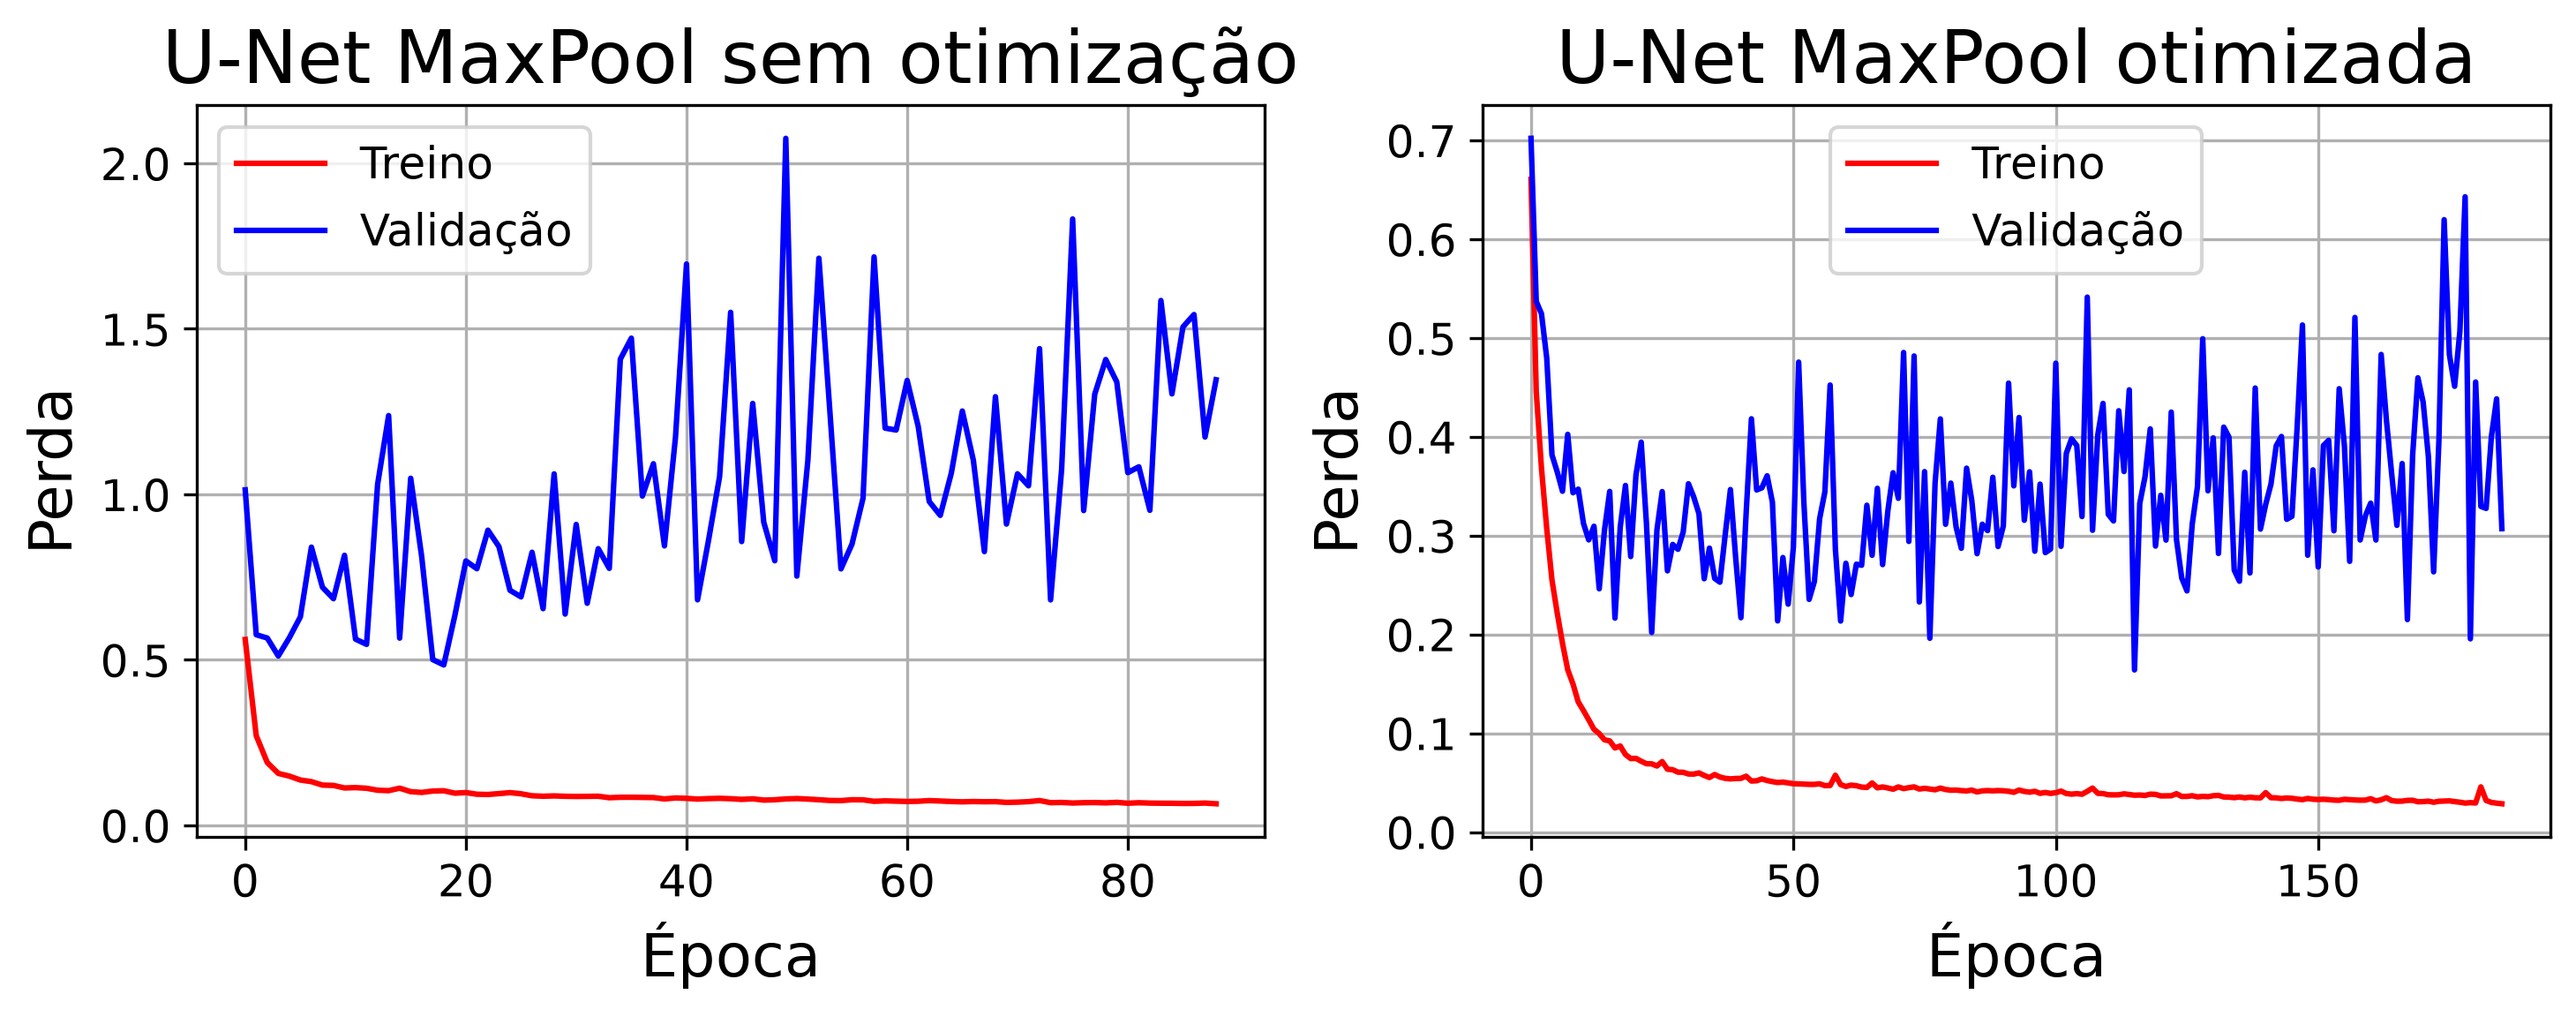

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

x0 = pontos = np.linspace(0, len(df_sem_otim["Treino"]) - 1, num=len(df_sem_otim["Treino"]))
axes[0].plot(x0, df_sem_otim["Treino"], color="Red", label="Treino")
axes[0].plot(x0, df_sem_otim["Validação"], color="Blue", label="Validação")
axes[0].legend()
axes[0].set_title("U-Net MaxPool sem otimização", fontsize=20)
axes[0].set_ylabel("Perda", fontsize=16)
axes[0].set_xlabel("Época", fontsize=16)
axes[0].grid(0.3)

x1 = pontos = np.linspace(0, len(df_otimizado["Treino"]) - 1, num=len(df_otimizado["Treino"]))
axes[1].plot(x1, df_otimizado["Treino"], color="Red", label="Treino")
axes[1].plot(x1, df_otimizado["Validação"], color="Blue", label="Validação")
axes[1].legend()
axes[1].set_title("U-Net MaxPool otimizada", fontsize=20)
axes[1].set_ylabel("Perda", fontsize=16)
axes[1].set_xlabel("Época", fontsize=16)
axes[1].grid(0.3)

plt.tight_layout()
plt.show()

### **Carregamento dos dados**

In [38]:
dados_mos2 = np.load(
        "mos2_dataset_0.npz"
        )

print("Carregou os dados", flush=True)

imagens_mos2 = dados_mos2["images"].astype(np.float32)
mascaras_mos2 = dados_mos2["labels"].astype(np.float32)

del dados_mos2

print("Carregou imagens e rótulos", flush=True)

print("imagens:", imagens_mos2.shape, imagens_mos2.dtype, imagens_mos2.nbytes / 1024**3, "GB")
print("mascaras:", mascaras_mos2.shape, mascaras_mos2.dtype, mascaras_mos2.nbytes / 1024**3, "GB")

imagens_treino_mos2, imagens_val_mos2, mascaras_treino_mos2, mascaras_val_mos2 = train_test_split(
            imagens_mos2,
            mascaras_mos2,
            test_size=0.1,
            random_state=42
        )

print("treino:", imagens_treino_mos2.nbytes / 1024**3, "GB")
print("val:", imagens_val_mos2.nbytes / 1024**3, "GB")

del imagens_mos2
del mascaras_mos2

imagens_val_mos2 = torch.from_numpy(imagens_val_mos2)

mascaras_val_mos2 = torch.from_numpy(mascaras_val_mos2)

if imagens_val_mos2.ndim == 3:

    imagens_val_mos2 = imagens_val_mos2.unsqueeze(1)

if mascaras_val_mos2.ndim == 3:

    mascaras_val_mos2 = mascaras_val_mos2.unsqueeze(1)

dataset_val_mos2 = TensorDataset(imagens_val_mos2, mascaras_val_mos2)

loader_val_mos2 = DataLoader(
    dataset_val_mos2,
    batch_size=8,
    shuffle=False
)

Carregou os dados
Carregou imagens e rótulos
imagens: (400, 1, 512, 512) float32 0.390625 GB
mascaras: (400, 1, 512, 512) float32 0.390625 GB
treino: 0.3515625 GB
val: 0.0390625 GB


### **U-Net MaxPool MoS2 (Sem otimização)**

In [39]:
# Salva a função original
_load_from_bytes_original_ = torch.storage._load_from_bytes

# Substitui temporariamente por uma versão que força CPU
torch.storage._load_from_bytes = lambda b: torch.load(
    io.BytesIO(b),
    map_location=torch.device("cpu"),
    weights_only=False
)

try:
    with open("U_Net_MaxPool_mos2_sem_otimizacao.pkl", "rb") as modelo:
        UNet_mos2_sem_otim = pickle.load(modelo)
finally:
    # Restaura a função original
    torch.storage._load_from_bytes = _load_from_bytes_original_

UNet_mos2_sem_otim = UNet_mos2_sem_otim.to("cpu")
UNet_mos2_sem_otim.eval()

UNet(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)

### **U-Net MaxPool Grafeno (Otimizada)**

In [40]:
# Salva a função original
_load_from_bytes_original = torch.storage._load_from_bytes

# Substitui temporariamente por uma versão que força CPU
torch.storage._load_from_bytes = lambda b: torch.load(
    io.BytesIO(b),
    map_location=torch.device("cpu"),
    weights_only=False
)

try:
    with open("U_Net_MaxPool_mos2.pkl", "rb") as modelo:
        UNet_mos2_otimizada = pickle.load(modelo)
finally:
    # Restaura a função original
    torch.storage._load_from_bytes = _load_from_bytes_original

UNet_mos2_otimizada = UNet_mos2_otimizada.to("cpu")
UNet_mos2_otimizada.eval()

UNet(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU6(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=Tr

### **Previsões**

In [41]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

acuracia_multiclasse = Accuracy(task="multiclass", num_classes=3, average=None).to(device)
sensibilidade_multiclasse = Recall(task="multiclass", num_classes=3, average=None).to(device)
especificidade_multiclasse = Specificity(task="multiclass", num_classes=3, average=None).to(device)
precisao_multiclasse = Precision(task="multiclass", num_classes=3, average=None).to(device)
f1_multiclasse = F1Score(task="multiclass", num_classes=3, average=None).to(device)
dice_multiclasse = DiceScore(num_classes=3, include_background=True, average=None, input_format="index").to(device)

##### **U-Net sem otimização**

In [42]:
acuracia_multiclasse.reset()
sensibilidade_multiclasse.reset()
especificidade_multiclasse.reset()
precisao_multiclasse.reset()
f1_multiclasse.reset()
dice_multiclasse.reset()

previsoes_mos2_sem_otim = []
rotulos_reais_mos2_sem_otim = []

with torch.no_grad():

    for imgs, mascaras in loader_val_mos2:

        imgs = imgs.to(device)
        mascaras = mascaras.to(device).long()

        if mascaras.ndim == 4 and mascaras.shape[1] == 1:
            mascaras = mascaras.squeeze(1)

        saida = UNet_mos2_sem_otim(imgs)

        probs = torch.softmax(saida, dim=1)
        preds = torch.argmax(probs, dim=1).long()

        previsoes_mos2_sem_otim.extend(preds.cpu().numpy())
        rotulos_reais_mos2_sem_otim.extend(mascaras.cpu().numpy())

        acuracia_multiclasse.update(preds, mascaras)
        sensibilidade_multiclasse.update(preds, mascaras)
        especificidade_multiclasse.update(preds, mascaras)
        precisao_multiclasse.update(preds, mascaras)
        f1_multiclasse.update(preds, mascaras)
        dice_multiclasse.update(preds, mascaras)

acuracia_mos2_sem_otim = acuracia_multiclasse.compute().cpu().tolist()
sensibilidade_mos2_sem_otim = sensibilidade_multiclasse.compute().cpu().tolist()
especificidade_mos2_sem_otim = especificidade_multiclasse.compute().cpu().tolist()
precisao_mos2_sem_otim = precisao_multiclasse.compute().cpu().tolist()
f1_mos2_sem_otim = f1_multiclasse.compute().cpu().tolist()
dice_mos2_sem_otim = dice_multiclasse.compute().cpu().tolist()

##### **U-Net otimizada**

In [43]:
acuracia_multiclasse.reset()
sensibilidade_multiclasse.reset()
especificidade_multiclasse.reset()
precisao_multiclasse.reset()
f1_multiclasse.reset()
dice_multiclasse.reset()

previsoes_mos2_otimizada = []
rotulos_reais_mos2_otimizada = []

with torch.no_grad():

    for imgs, mascaras in loader_val_mos2:

        imgs = imgs.to(device)
        mascaras = mascaras.to(device).long()

        if mascaras.ndim == 4 and mascaras.shape[1] == 1:
            mascaras = mascaras.squeeze(1)

        saida = UNet_mos2_otimizada(imgs)

        probs = torch.softmax(saida, dim=1)
        preds = torch.argmax(probs, dim=1).long()

        previsoes_mos2_otimizada.extend(preds.cpu().numpy())
        rotulos_reais_mos2_otimizada.extend(mascaras.cpu().numpy())

        acuracia_multiclasse.update(preds, mascaras)
        sensibilidade_multiclasse.update(preds, mascaras)
        especificidade_multiclasse.update(preds, mascaras)
        precisao_multiclasse.update(preds, mascaras)
        f1_multiclasse.update(preds, mascaras)
        dice_multiclasse.update(preds, mascaras)

acuracia_mos2_otimizada = acuracia_multiclasse.compute().cpu().tolist()
sensibilidade_mos2_otimizada = sensibilidade_multiclasse.compute().cpu().tolist()
especificidade_mos2_otimizada = especificidade_multiclasse.compute().cpu().tolist()
precisao_mos2_otimizada = precisao_multiclasse.compute().cpu().tolist()
f1_mos2_otimizada = f1_multiclasse.compute().cpu().tolist()
dice_mos2_otimizada = dice_multiclasse.compute().cpu().tolist()

### **Análise de resultados**

##### **Métricas**

In [44]:
acc0_mos2_sem_otim = acuracia_mos2_sem_otim[0]
acc1_mos2_sem_otim = acuracia_mos2_sem_otim[1]
acc2_mos2_sem_otim = acuracia_mos2_sem_otim[2]

sen0_mos2_sem_otim = sensibilidade_mos2_sem_otim[0]
sen1_mos2_sem_otim = sensibilidade_mos2_sem_otim[1]
sen2_mos2_sem_otim = sensibilidade_mos2_sem_otim[2]

esp0_mos2_sem_otim = especificidade_mos2_sem_otim[0]
esp1_mos2_sem_otim = especificidade_mos2_sem_otim[1]
esp2_mos2_sem_otim = especificidade_mos2_sem_otim[2]

pre0_mos2_sem_otim = precisao_mos2_sem_otim[0]
pre1_mos2_sem_otim = precisao_mos2_sem_otim[1]
pre2_mos2_sem_otim = precisao_mos2_sem_otim[2]

f1_0_mos2_sem_otim = f1_mos2_sem_otim[0]
f1_1_mos2_sem_otim = f1_mos2_sem_otim[1]
f1_2_mos2_sem_otim = f1_mos2_sem_otim[2]

dice_0_mos2_sem_otim = dice_mos2_sem_otim[0]
dice_1_mos2_sem_otim = dice_mos2_sem_otim[1]
dice_2_mos2_sem_otim = dice_mos2_sem_otim[2]

In [45]:
acc0_mos2_otimizada = acuracia_mos2_otimizada[0]
acc1_mos2_otimizada = acuracia_mos2_otimizada[1]
acc2_mos2_otimizada = acuracia_mos2_otimizada[2]

sen0_mos2_otimizada = sensibilidade_mos2_otimizada[0]
sen1_mos2_otimizada = sensibilidade_mos2_otimizada[1]
sen2_mos2_otimizada = sensibilidade_mos2_otimizada[2]

esp0_mos2_otimizada = especificidade_mos2_otimizada[0]
esp1_mos2_otimizada = especificidade_mos2_otimizada[1]
esp2_mos2_otimizada = especificidade_mos2_otimizada[2]

pre0_mos2_otimizada = precisao_mos2_otimizada[0]
pre1_mos2_otimizada = precisao_mos2_otimizada[1]
pre2_mos2_otimizada = precisao_mos2_otimizada[2]

f1_0_mos2_otimizada = f1_mos2_otimizada[0]
f1_1_mos2_otimizada = f1_mos2_otimizada[1]
f1_2_mos2_otimizada = f1_mos2_otimizada[2]

dice_0_mos2_otimizada = dice_mos2_otimizada[0]
dice_1_mos2_otimizada = dice_mos2_otimizada[1]
dice_2_mos2_otimizada = dice_mos2_otimizada[2]

In [46]:
print("Rede sem otimização:")
print(f"Classe 0: ")
print(f"Acurácia={acc0_mos2_sem_otim*100}%")
print(f"Sensibilidade={sen0_mos2_sem_otim*100}%")
print(f"Especificidade={esp0_mos2_sem_otim*100:.2f}%")
print(f"Precisão={pre0_mos2_sem_otim*100:.2f}%")
print(f"F1={f1_0_mos2_sem_otim*100:.2f}%")
print(f"Dice={dice_0_mos2_sem_otim*100:.2f}%")
print()

print(f"Classe 1: ")
print(f"Acurácia={acc1_mos2_sem_otim*100:.2f}%")
print(f"Sensibilidade={sen1_mos2_sem_otim*100:.2f}%")
print(f"Especificidade={esp1_mos2_sem_otim*100:.2f}%")
print(f"Precisão={pre1_mos2_sem_otim*100:.2f}%")
print(f"F1={f1_1_mos2_sem_otim*100:.2f}%")
print(f"Dice={dice_1_mos2_sem_otim*100:.2f}%")
print()

print(f"Classe 2: ")
print(f"Acurácia={acc2_mos2_sem_otim*100:.2f}%")
print(f"Sensibilidade={sen2_mos2_sem_otim*100:.2f}%")
print(f"Especificidade={esp2_mos2_sem_otim*100:.2f}%")
print(f"Precisão={pre2_mos2_sem_otim*100:.2f}%")
print(f"F1={f1_2_mos2_sem_otim*100:.2f}%")
print(f"Dice={dice_2_mos2_sem_otim*100:.2f}%")

Rede sem otimização:
Classe 0: 
Acurácia=64.86786603927612%
Sensibilidade=64.86786603927612%
Especificidade=96.98%
Precisão=71.97%
F1=68.24%
Dice=63.71%

Classe 1: 
Acurácia=84.07%
Sensibilidade=84.07%
Especificidade=92.28%
Precisão=81.29%
F1=82.66%
Dice=82.92%

Classe 2: 
Acurácia=90.88%
Sensibilidade=90.88%
Especificidade=85.65%
Precisão=90.77%
F1=90.82%
Dice=90.44%


In [47]:
print("Rede otimizada:")
print(f"Classe 0: ")
print(f"Acurácia={acc0_mos2_otimizada*100}%")
print(f"Sensibilidade={sen0_mos2_otimizada*100}%")
print(f"Especificidade={esp0_mos2_otimizada*100:.2f}%")
print(f"Precisão={pre0_mos2_otimizada*100:.2f}%")
print(f"F1={f1_0_mos2_otimizada*100:.2f}%")
print(f"Dice={dice_0_mos2_otimizada*100:.2f}%")
print()

print(f"Classe 1: ")
print(f"Acurácia={acc1_mos2_otimizada*100:.2f}%")
print(f"Sensibilidade={sen1_mos2_otimizada*100:.2f}%")
print(f"Especificidade={esp1_mos2_otimizada*100:.2f}%")
print(f"Precisão={pre1_mos2_otimizada*100:.2f}%")
print(f"F1={f1_1_mos2_otimizada*100:.2f}%")
print(f"Dice={dice_1_mos2_otimizada*100:.2f}%")
print()

print(f"Classe 2: ")
print(f"Acurácia={acc2_mos2_otimizada*100:.2f}%")
print(f"Sensibilidade={sen2_mos2_otimizada*100:.2f}%")
print(f"Especificidade={esp2_mos2_otimizada*100:.2f}%")
print(f"Precisão={pre2_mos2_otimizada*100:.2f}%")
print(f"F1={f1_2_mos2_otimizada*100:.2f}%")
print(f"Dice={dice_2_mos2_otimizada*100:.2f}%")

Rede otimizada:
Classe 0: 
Acurácia=92.13147759437561%
Sensibilidade=92.13147759437561%
Especificidade=98.76%
Precisão=89.83%
F1=90.97%
Dice=91.02%

Classe 1: 
Acurácia=92.22%
Sensibilidade=92.22%
Especificidade=98.97%
Precisão=97.27%
F1=94.68%
Dice=94.26%

Classe 2: 
Acurácia=98.03%
Sensibilidade=98.03%
Especificidade=93.87%
Precisão=96.12%
F1=97.07%
Dice=97.09%


##### **Matriz de confusão**

In [48]:
confmat_multiclasse = torchmetrics.ConfusionMatrix(
    task="multiclass",
    num_classes=3,
    normalize = "all"
).to(device)

In [49]:
previsoes_array_mos2_sem_otim = np.asarray(previsoes_mos2_sem_otim)
rotulos_array_mos2_sem_otim = np.asarray(rotulos_reais_mos2_sem_otim)

previsoes_array_mos2_sem_otim = previsoes_array_mos2_sem_otim.astype(np.float64)
rotulos_array_mos2_sem_otim = rotulos_array_mos2_sem_otim.astype(np.int64)

previsoes_tensor_mos2_sem_otim = torch.tensor(
    previsoes_array_mos2_sem_otim,
    dtype=torch.long,
    device=device
)

rotulos_tensor_mos2_sem_otim = torch.tensor(
    rotulos_array_mos2_sem_otim,
    dtype=torch.long,
    device=device
)

if previsoes_tensor_mos2_sem_otim.ndim == 4 and previsoes_tensor_mos2_sem_otim.shape[1] == 1:
    previsoes_tensor_mos2_sem_otim = previsoes_tensor_mos2_sem_otim.squeeze(1)

if rotulos_tensor_mos2_sem_otim.ndim == 4 and rotulos_tensor_mos2_sem_otim.shape[1] == 1:
    rotulos_tensor_mos2_sem_otim = rotulos_tensor_mos2_sem_otim.squeeze(1)

cm_mos2_sem_otim = confmat_multiclasse(
    previsoes_tensor_mos2_sem_otim,
    rotulos_tensor_mos2_sem_otim
)

In [50]:
previsoes_array_mos2_otimizada = np.asarray(previsoes_mos2_otimizada)
rotulos_array_mos2_otimizada = np.asarray(rotulos_reais_mos2_otimizada)

previsoes_array_mos2_otimizada = previsoes_array_mos2_otimizada.astype(np.float64)
rotulos_array_mos2_otimizada = rotulos_array_mos2_otimizada.astype(np.int64)

previsoes_tensor_mos2_otimizada = torch.tensor(
    previsoes_array_mos2_otimizada,
    dtype=torch.long,
    device=device
)

rotulos_tensor_mos2_otimizada = torch.tensor(
    rotulos_array_mos2_otimizada,
    dtype=torch.long,
    device=device
)

if previsoes_tensor_mos2_otimizada.ndim == 4 and previsoes_tensor_mos2_otimizada.shape[1] == 1:
    previsoes_tensor_mos2_otimizada = previsoes_tensor_mos2_otimizada.squeeze(1)

if rotulos_tensor_mos2_otimizada.ndim == 4 and rotulos_tensor_mos2_otimizada.shape[1] == 1:
    rotulos_tensor_mos2_otimizada = rotulos_tensor_mos2_otimizada.squeeze(1)

cm_mos2_otimizada = confmat_multiclasse(
    previsoes_tensor_mos2_otimizada,
    rotulos_tensor_mos2_otimizada
)

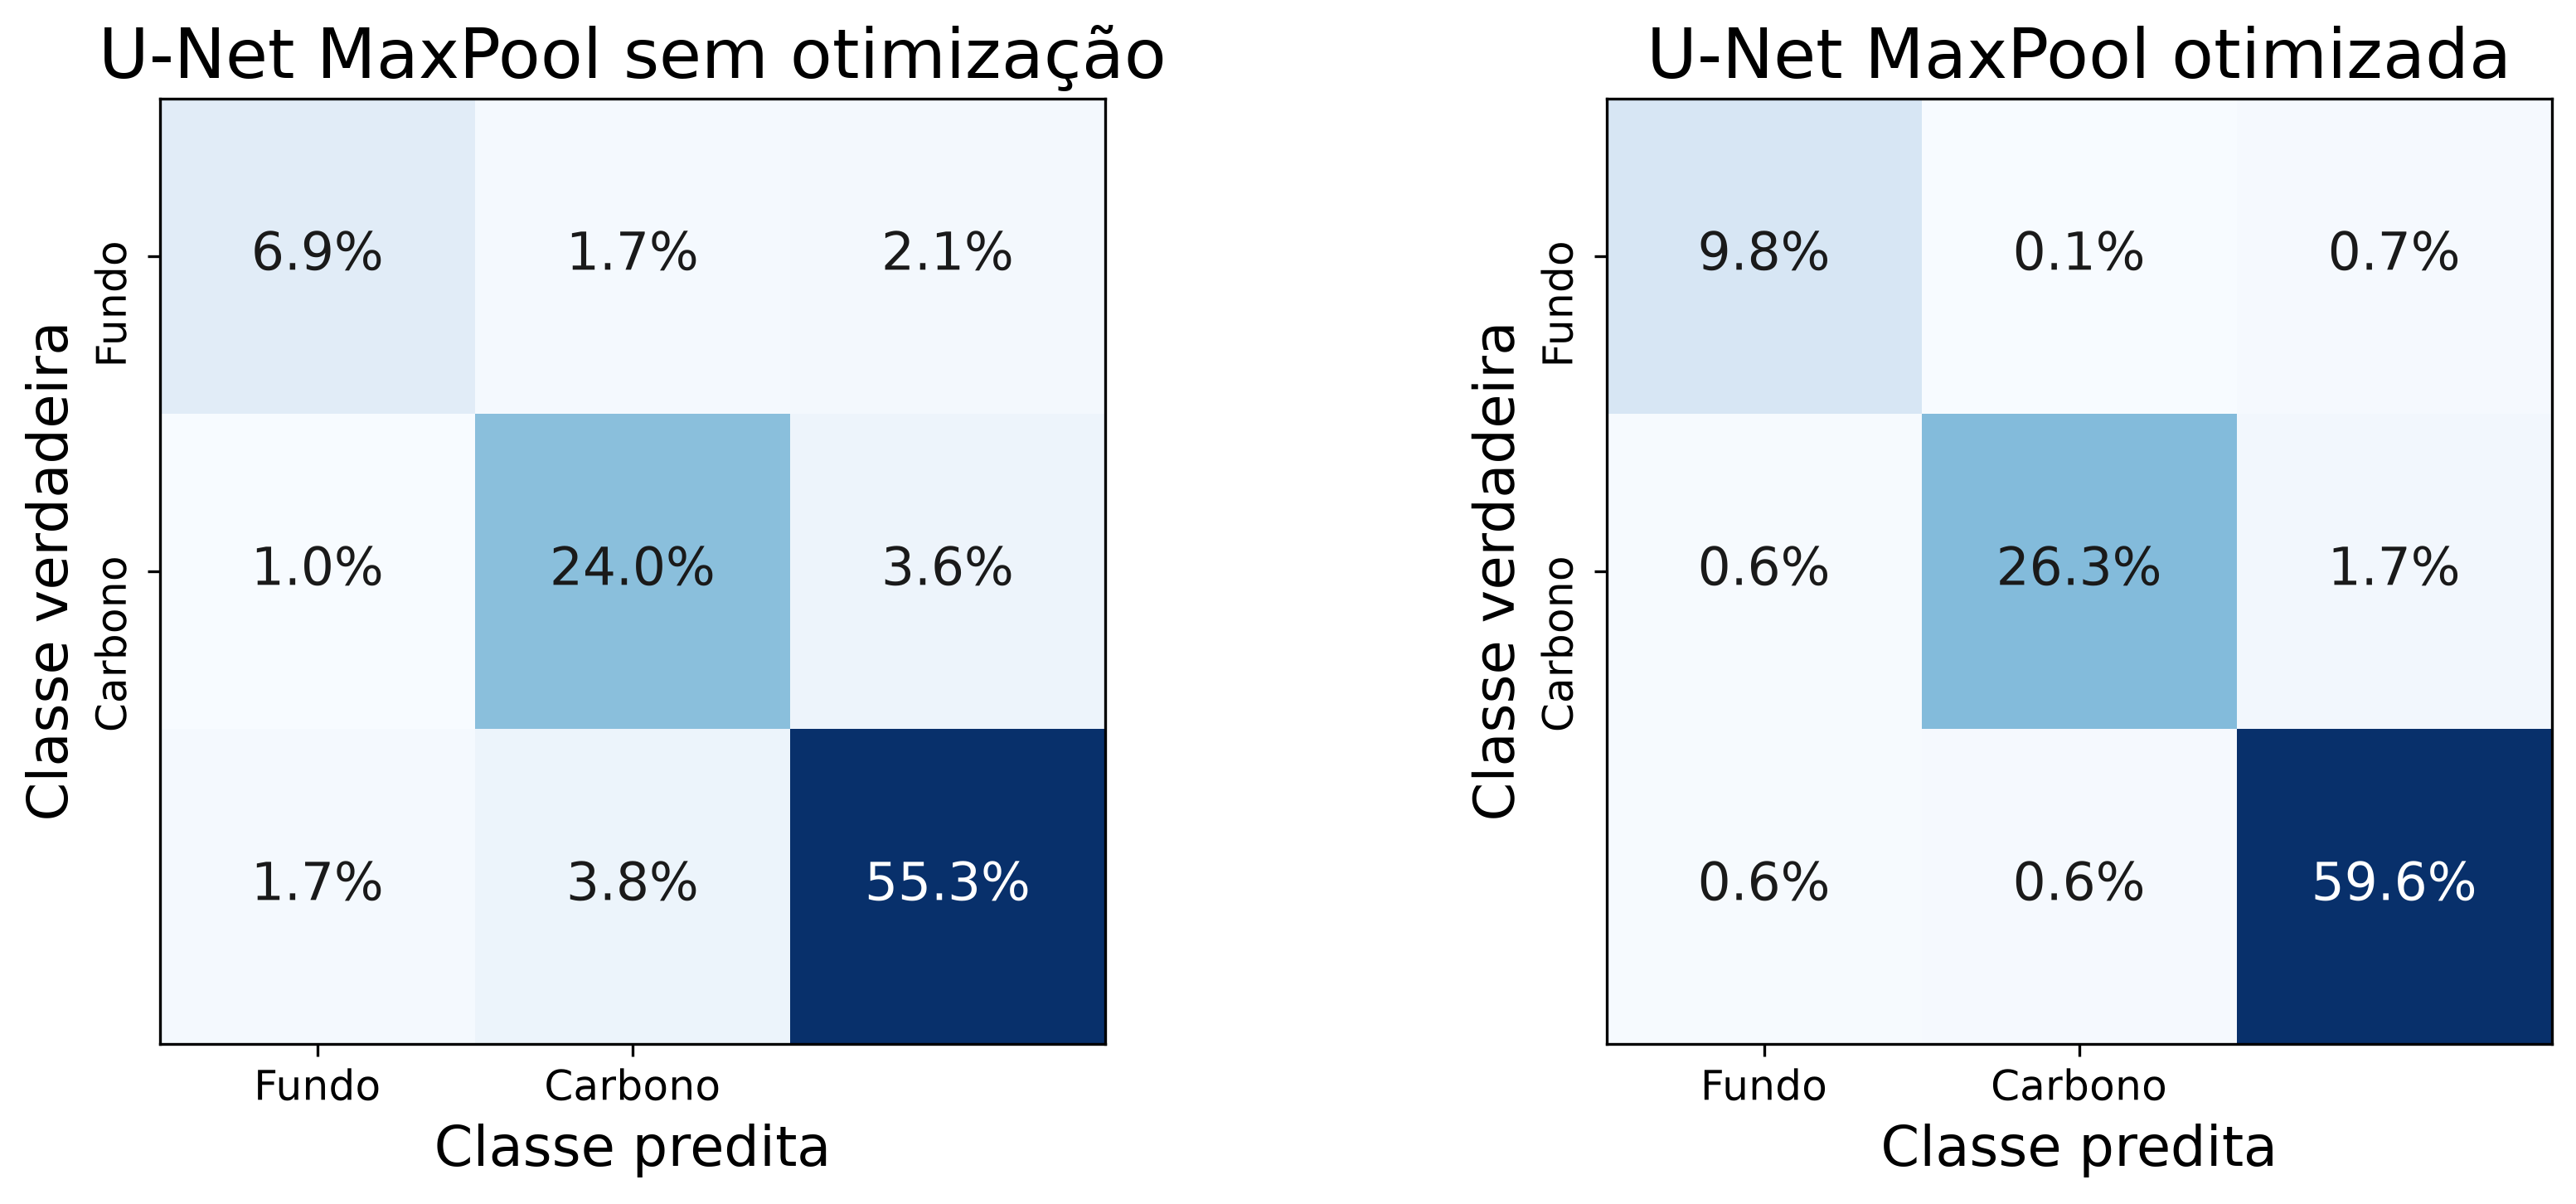

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

confmat_multiclasse.plot(
    cm_mos2_otimizada,
    ax=axes[1],
    cmap="Blues",
    add_text=True
)

axes[1].set_title("U-Net MaxPool otimizada", fontsize=20)
axes[1].set_ylabel("Classe verdadeira", fontsize=16)
axes[1].set_xlabel("Classe predita", fontsize=16)

axes[1].set_xticks([0, 1], ["Fundo", "Carbono"], rotation=0, fontsize=12)
axes[1].set_yticks([0, 1], ["Fundo", "Carbono"], rotation=90, fontsize=12)


confmat_multiclasse.plot(
    cm_mos2_sem_otim,
    ax=axes[0],
    cmap="Blues",
    add_text=True
)


for texto, valor in zip(axes[0].texts, cm_mos2_sem_otim.flatten()):
    texto.set_text(f"{valor.item() * 100:.1f}%")

    
for texto, valor in zip(axes[1].texts, cm_mos2_otimizada.flatten()):
    texto.set_text(f"{valor.item() * 100:.1f}%")

axes[0].set_title("U-Net MaxPool sem otimização", fontsize=20)
axes[0].set_xlabel("Classe predita", fontsize=16)
axes[0].set_ylabel("Classe verdadeira", fontsize=16)


axes[0].set_xticks([0, 1], ["Fundo", "Carbono"], rotation=0, fontsize=12)
axes[0].set_yticks([0, 1], ["Fundo", "Carbono"], rotation=90, fontsize=12)

plt.tight_layout()

plt.savefig(
    "matrizes_confusao_mos2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##### **Sobreposição entre a imagem real e a máscara**

*U-Net sem otimização*

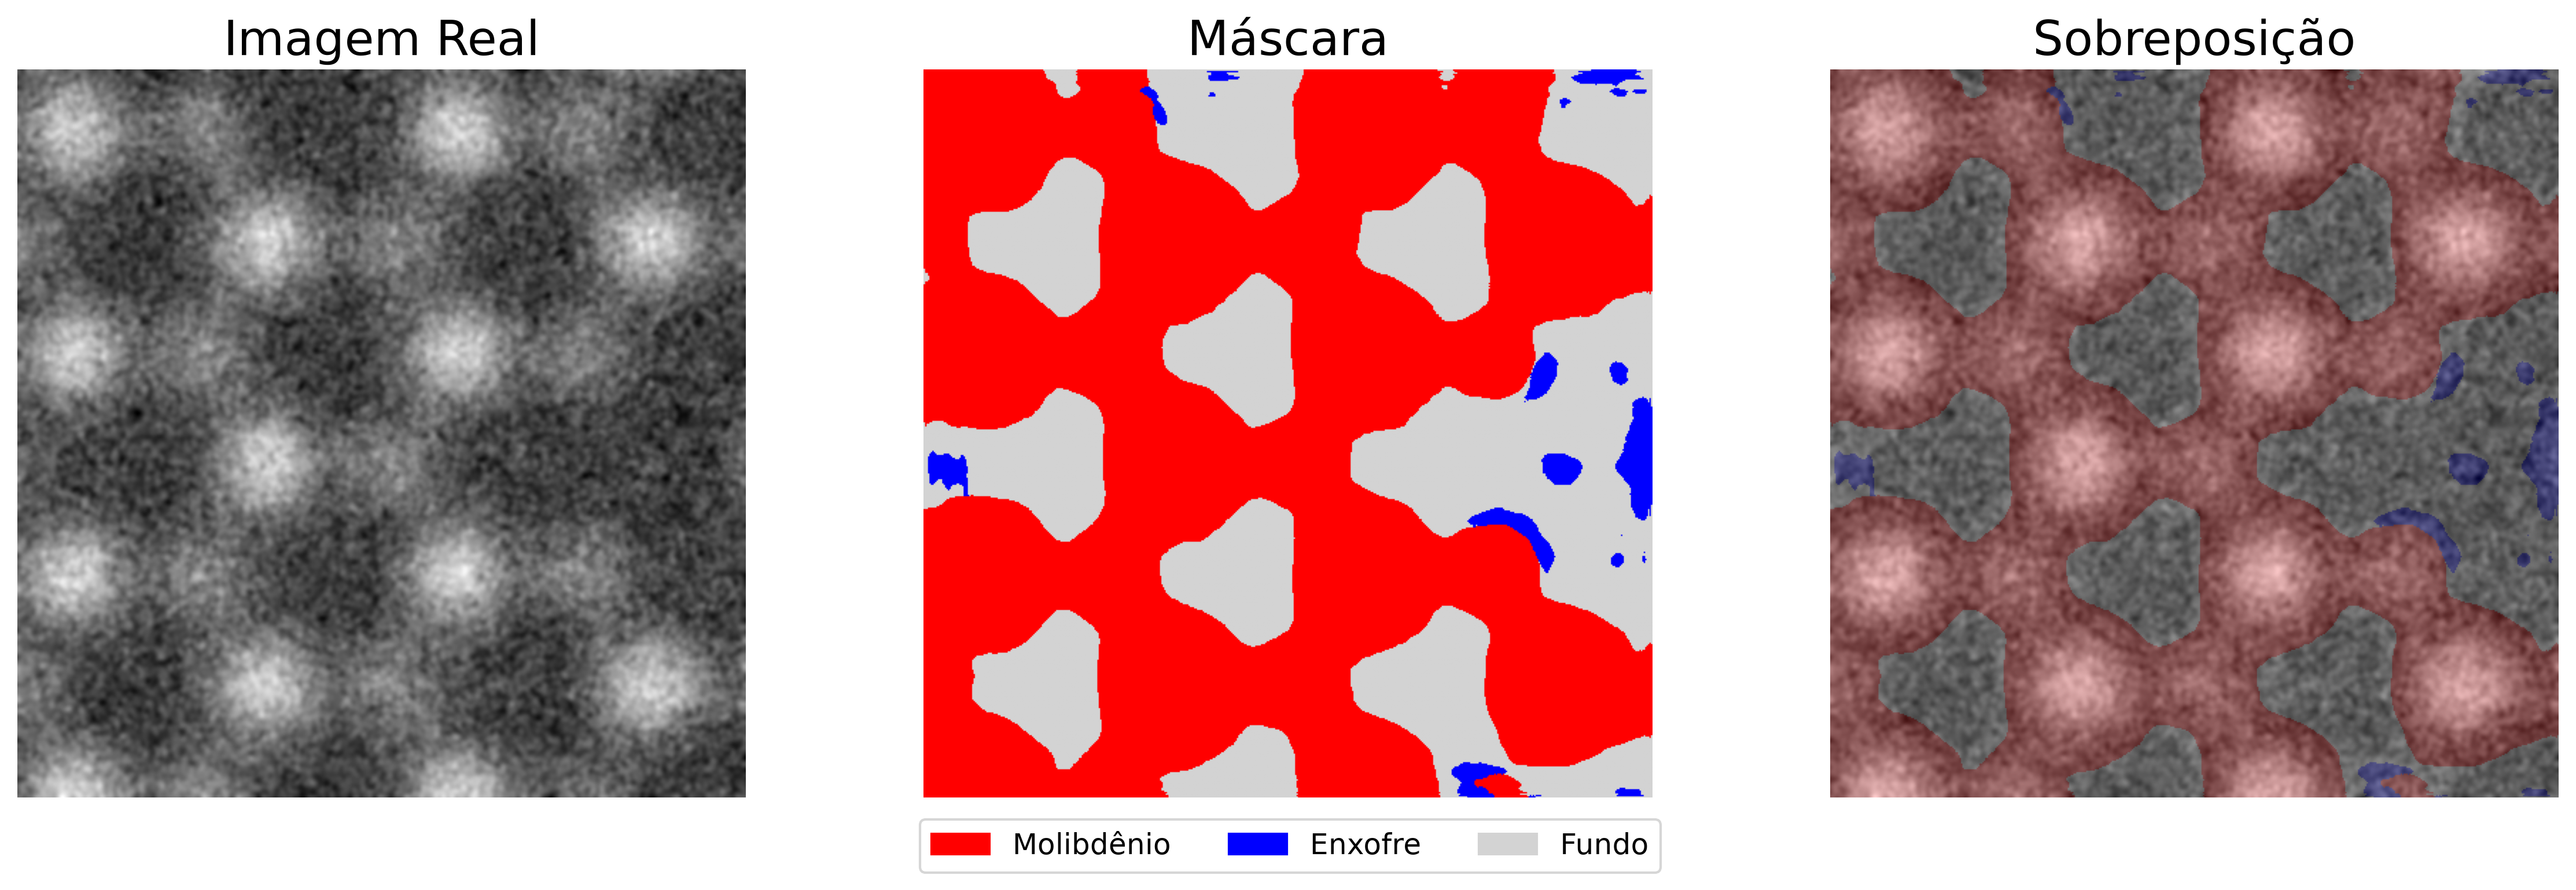

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

colormap_mos2 = ListedColormap(["blue", "red", "lightgray"])

axes[0].imshow(imagens_val_mos2[0][0], cmap="gray")
axes[0].set_title("Imagem Real", fontsize=20)
axes[0].axis("off")

legenda0 = mpatches.Patch(color="red", label="Molibdênio")
legenda1 = mpatches.Patch(color="blue", label="Enxofre")
legenda2 = mpatches.Patch(color="lightgray", label="Fundo")

axes[1].imshow(previsoes_mos2_sem_otim[0], origin='upper', cmap=colormap_mos2)
axes[1].set_title("Máscara", fontsize=20)
axes[1].axis("off")

axes[1].legend(
    handles=[legenda0, legenda1, legenda2],
    loc="upper left",
    fontsize=12,
    bbox_to_anchor=(-0.025, -0.01),
    ncols=3
)

axes[2].imshow(imagens_val_mos2[0][0], cmap="gray")
axes[2].imshow(previsoes_mos2_sem_otim[0], origin='upper', alpha=0.2, cmap=colormap_mos2)

axes[2].set_title("Sobreposição", fontsize=20)
axes[2].axis("off")

plt.tight_layout()
plt.show()

*U-Net otimizada*

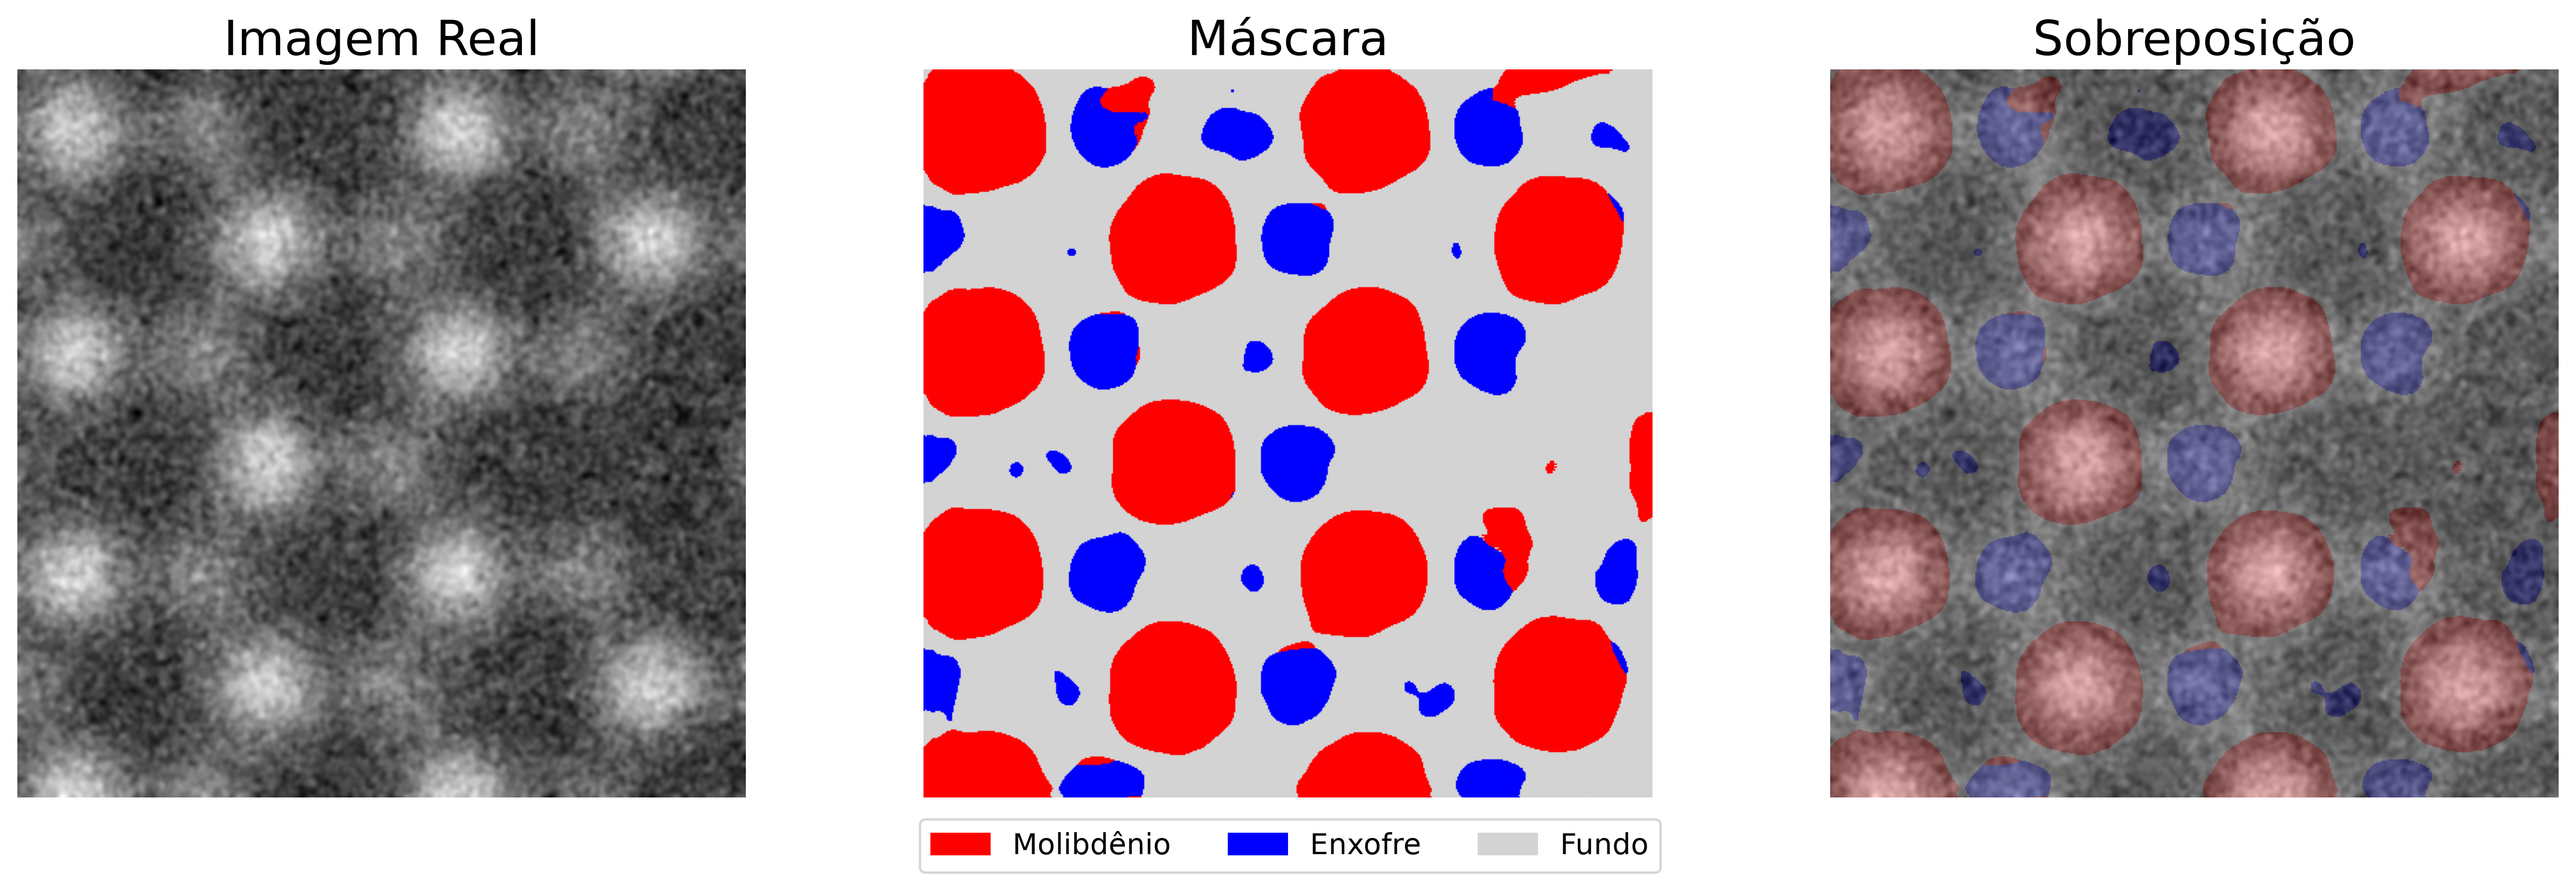

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

colormap_mos2 = ListedColormap(["blue", "red", "lightgray"])

axes[0].imshow(imagens_val_mos2[0][0], cmap="gray")
axes[0].set_title("Imagem Real", fontsize=20)
axes[0].axis("off")

legenda0 = mpatches.Patch(color="red", label="Molibdênio")
legenda1 = mpatches.Patch(color="blue", label="Enxofre")
legenda2 = mpatches.Patch(color="lightgray", label="Fundo")

axes[1].imshow(previsoes_mos2_otimizada[0], origin='upper', cmap=colormap_mos2)
axes[1].set_title("Máscara", fontsize=20)
axes[1].axis("off")

axes[1].legend(
    handles=[legenda0, legenda1, legenda2],
    loc="upper left",
    fontsize=12,
    bbox_to_anchor=(-0.025, -0.01),
    ncols=3
)

axes[2].imshow(imagens_val_mos2[0][0], cmap="gray")
axes[2].imshow(previsoes_mos2_otimizada[0], origin='upper', alpha=0.2, cmap=colormap_mos2)

axes[2].set_title("Sobreposição", fontsize=20)
axes[2].axis("off")

plt.tight_layout()
plt.show()

##### **Gráfico de subtração**

In [54]:
grafico_sobreposicao_sem_otim = np.zeros_like(mascaras_val_mos2[0][0])

grafico_sobreposicao_sem_otim = np.where(
    (mascaras_val_mos2[0][0] == 0) & (previsoes_mos2_sem_otim[0] == 0),
    0,
    grafico_sobreposicao_sem_otim
)

grafico_sobreposicao_sem_otim = np.where(
    (mascaras_val_mos2[0][0] == 0) & (previsoes_mos2_sem_otim[0] == 1),
    1,
    grafico_sobreposicao_sem_otim
)

grafico_sobreposicao_sem_otim = np.where(
    (mascaras_val_mos2[0][0] == 0) & (previsoes_mos2_sem_otim[0] == 2),
    2,
    grafico_sobreposicao_sem_otim
)

grafico_sobreposicao_sem_otim = np.where(
    (mascaras_val_mos2[0][0] == 1) & (previsoes_mos2_sem_otim[0] == 0),
    3,
    grafico_sobreposicao_sem_otim
)

grafico_sobreposicao_sem_otim = np.where(
    (mascaras_val_mos2[0][0] == 1) & (previsoes_mos2_sem_otim[0] == 1),
    4,
    grafico_sobreposicao_sem_otim
)

grafico_sobreposicao_sem_otim = np.where(
    (mascaras_val_mos2[0][0] == 1) & (previsoes_mos2_sem_otim[0] == 2),
    5,
    grafico_sobreposicao_sem_otim
)

grafico_sobreposicao_sem_otim = np.where(
    (mascaras_val_mos2[0][0] == 2) & (previsoes_mos2_sem_otim[0] == 0),
    6,
    grafico_sobreposicao_sem_otim
)

grafico_sobreposicao_sem_otim = np.where(
    (mascaras_val_mos2[0][0] == 2) & (previsoes_mos2_sem_otim[0] == 1),
    7,
    grafico_sobreposicao_sem_otim
)

grafico_sobreposicao_sem_otim = np.where(
    (mascaras_val_mos2[0][0] == 2) & (previsoes_mos2_sem_otim[0] == 2),
    8,
    grafico_sobreposicao_sem_otim
)

C:\Users\julia24002\AppData\Local\Temp\ipykernel_31820\1649355923.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  (mascaras_val_mos2[0][0] == 0) & (previsoes_mos2_sem_otim[0] == 0),
C:\Users\julia24002\AppData\Local\Temp\ipykernel_31820\1649355923.py:10: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  (mascaras_val_mos2[0][0] == 0) & (previsoes_mos2_sem_otim[0] == 1),
C:\Users\julia24002\AppData\Local\Temp\ipykernel_31820\1649355923.py:16: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  (mascaras_val_mos2[0][0] == 0) & (previsoes_mos2_sem_otim[0] == 2),
C:\Users\julia24002\AppData\Local\Temp\ipykernel_31820\1649355923.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positio

In [55]:
grafico_sobreposicao_otimizada = np.zeros_like(mascaras_val_mos2[0][0])

grafico_sobreposicao_otimizada = np.where(
    (mascaras_val_mos2[0][0] == 0) & (previsoes_mos2_otimizada[0] == 0),
    0,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_val_mos2[0][0] == 0) & (previsoes_mos2_otimizada[0] == 1),
    1,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_val_mos2[0][0] == 0) & (previsoes_mos2_otimizada[0] == 2),
    2,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_val_mos2[0][0] == 1) & (previsoes_mos2_otimizada[0] == 0),
    3,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_val_mos2[0][0] == 1) & (previsoes_mos2_otimizada[0] == 1),
    4,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_val_mos2[0][0] == 1) & (previsoes_mos2_otimizada[0] == 2),
    5,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_val_mos2[0][0] == 2) & (previsoes_mos2_otimizada[0] == 0),
    6,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_val_mos2[0][0] == 2) & (previsoes_mos2_otimizada[0] == 1),
    7,
    grafico_sobreposicao_otimizada
)

grafico_sobreposicao_otimizada = np.where(
    (mascaras_val_mos2[0][0] == 2) & (previsoes_mos2_otimizada[0] == 2),
    8,
    grafico_sobreposicao_otimizada
)

C:\Users\julia24002\AppData\Local\Temp\ipykernel_31820\562181504.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  (mascaras_val_mos2[0][0] == 0) & (previsoes_mos2_otimizada[0] == 0),
C:\Users\julia24002\AppData\Local\Temp\ipykernel_31820\562181504.py:10: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  (mascaras_val_mos2[0][0] == 0) & (previsoes_mos2_otimizada[0] == 1),
C:\Users\julia24002\AppData\Local\Temp\ipykernel_31820\562181504.py:16: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  (mascaras_val_mos2[0][0] == 0) & (previsoes_mos2_otimizada[0] == 2),
C:\Users\julia24002\AppData\Local\Temp\ipykernel_31820\562181504.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (position

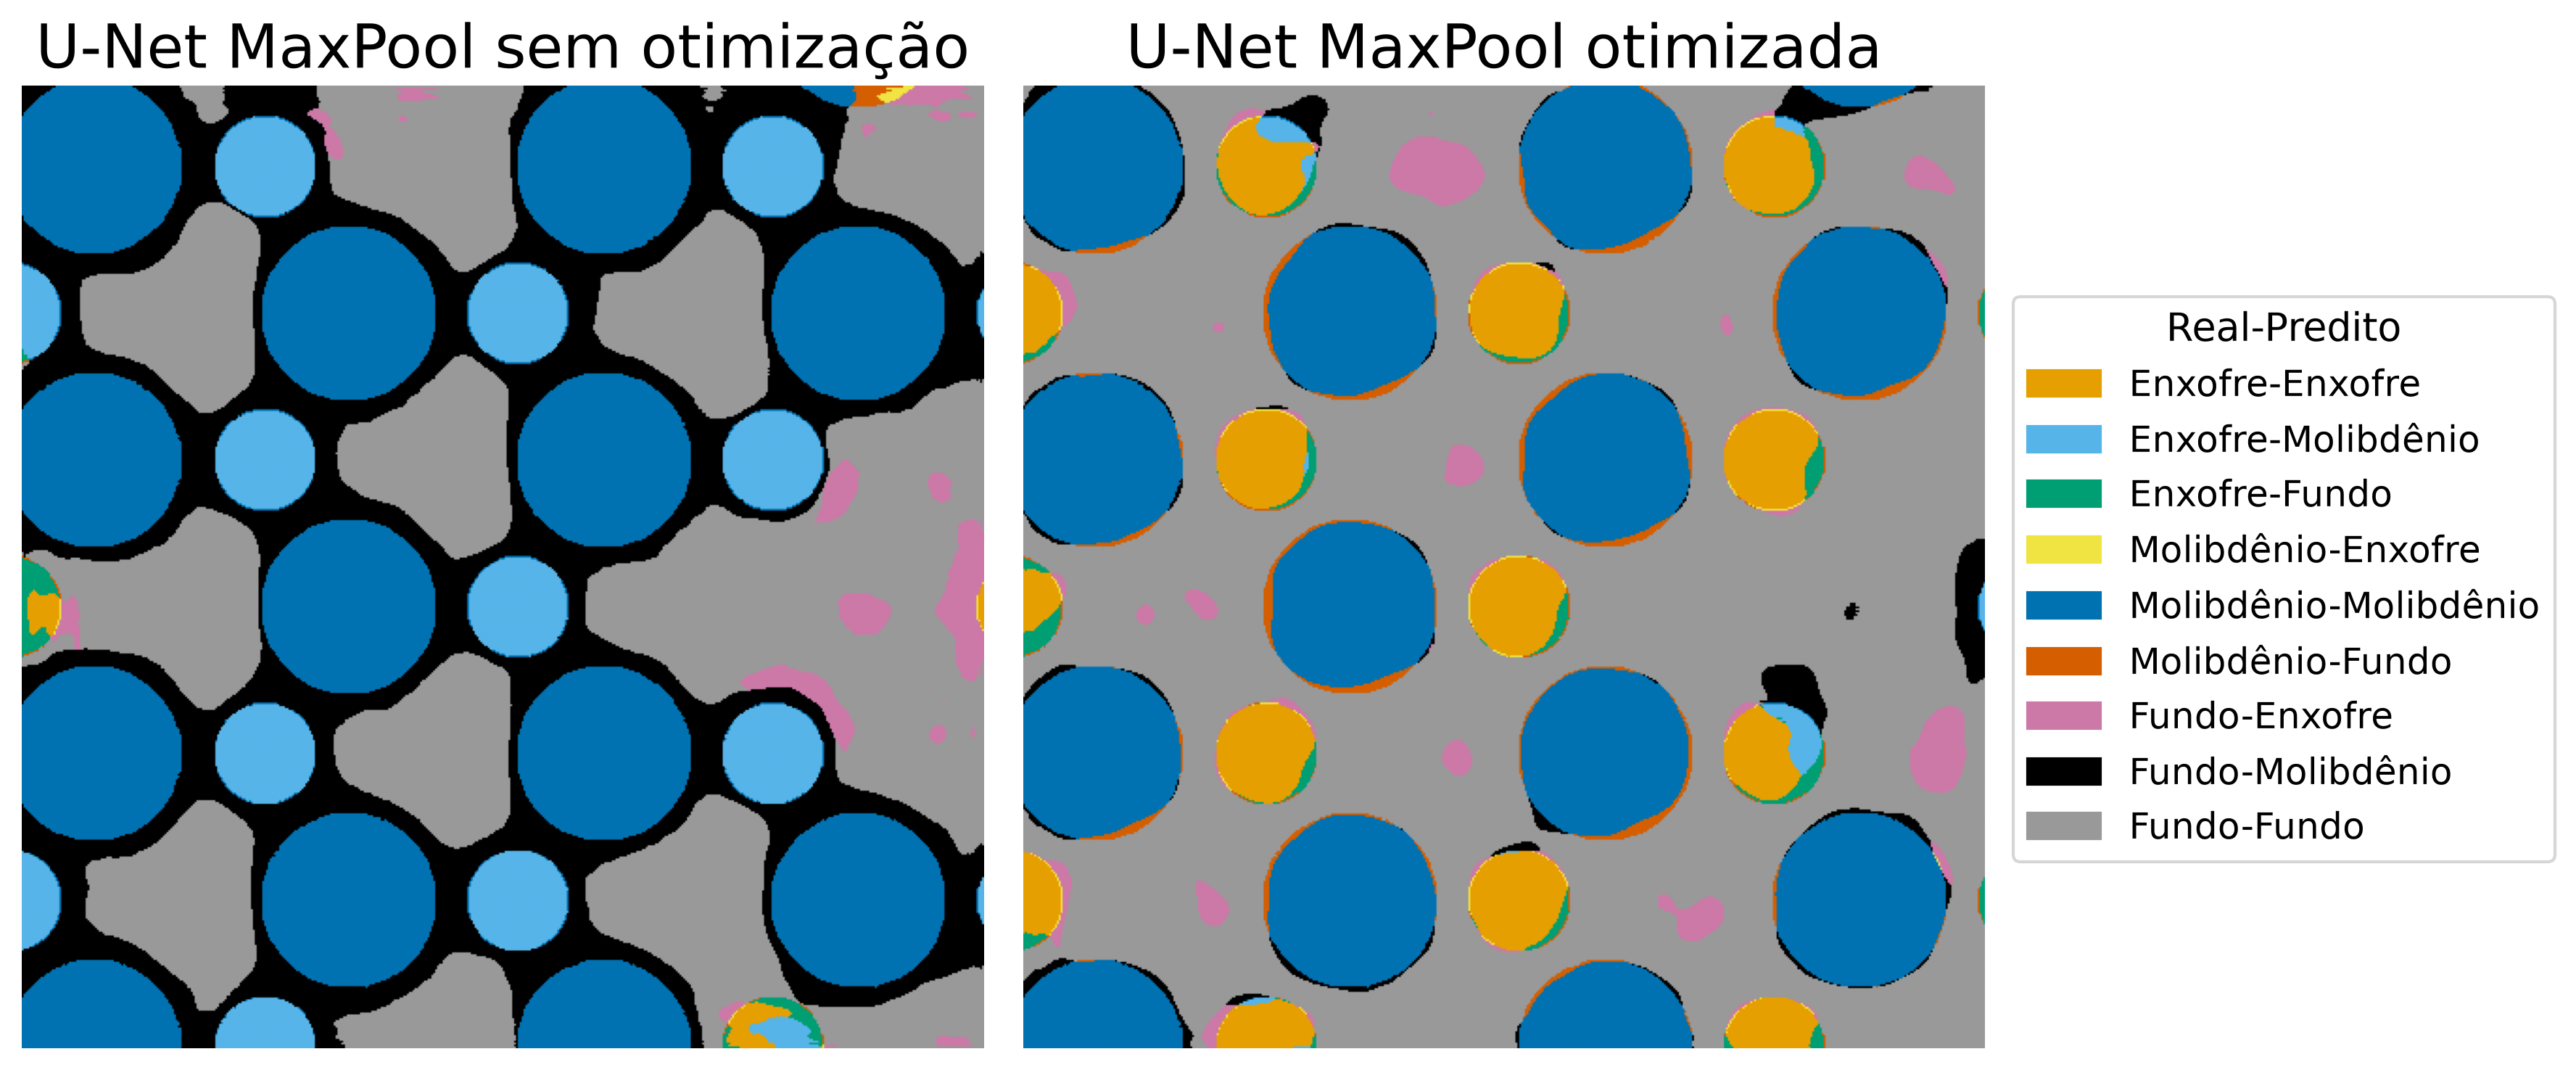

In [56]:

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

okabe_ito = ListedColormap([
    "#e69f00",
    "#56b4e9",
    "#009e73",
    "#f0e442",
    "#0072b2",
    "#d55e00",
    "#cc79a7",
    "#000000",
    "#999999"
])

legenda0 = mpatches.Patch(color="#e69f00", label="Enxofre-Enxofre")
legenda1 = mpatches.Patch(color="#56b4e9", label="Enxofre-Molibdênio")
legenda2 = mpatches.Patch(color="#009e73", label="Enxofre-Fundo")
legenda3 = mpatches.Patch(color="#f0e442", label="Molibdênio-Enxofre")
legenda4 = mpatches.Patch(color="#0072b2", label="Molibdênio-Molibdênio")
legenda5 = mpatches.Patch(color="#d55e00", label="Molibdênio-Fundo")
legenda6 = mpatches.Patch(color="#cc79a7", label="Fundo-Enxofre")
legenda7 = mpatches.Patch(color="#000000", label="Fundo-Molibdênio")
legenda8 = mpatches.Patch(color="#999999", label="Fundo-Fundo")

axes[0].imshow(
    grafico_sobreposicao_sem_otim,
    origin="upper",
    cmap=okabe_ito
)

axes[0].set_title("U-Net MaxPool sem otimização", fontsize=20)
axes[0].axis("off")

axes[1].legend(
    handles=[
        legenda0, legenda1, legenda2,
        legenda3, legenda4, legenda5,
        legenda6, legenda7, legenda8
    ],
    loc="upper left",
    fontsize=12,
    bbox_to_anchor=(1.01, 0.8),
    ncols=1,
    title="Real-Predito",
    title_fontsize=13
)

axes[1].imshow(
    grafico_sobreposicao_otimizada,
    origin="upper",
    cmap=okabe_ito
)

axes[1].set_title("U-Net MaxPool otimizada", fontsize=20)
axes[1].axis("off")


plt.tight_layout()
plt.show()